# BCSE331P – Exploratory Data Analysis
## Assessment 9: Principal Component Analysis
**Dataset:** `recid.csv` (1445 rows; columns: rownames, black, alcohol, drugs, super, married, felon, workprg, property, person, priors, educ, rules, age, tserved, follow, durat, cens, ldurat).

**Q1. Load the dataset and verify the required packages are loaded**  
(R: ggplot2, ggfortify, FactoMineR, factoextra → Python: matplotlib/seaborn for plotting, scikit-learn for PCA)

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
import sklearn, warnings; warnings.filterwarnings("ignore")
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
print("matplotlib", plt.matplotlib.__version__, "| seaborn", sns.__version__, "| scikit-learn", sklearn.__version__)

URL = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/recid.csv"
REG_NO = "22BCE0000"          # <-- put your registration number here
df = pd.read_csv(URL); df.head()

matplotlib 3.10.0 | seaborn 0.13.2 | scikit-learn 1.6.1


,rownames,black,alcohol,drugs,super,married,felon,workprg,property,person,priors,educ,rules,age,tserved,follow,durat,cens,ldurat
0,1,0,1,0,1,1,0,1,0,0,0,7,2,441,30,72,72,1,4.276666
1,2,1,0,0,1,0,1,1,1,0,0,12,0,307,19,75,75,1,4.317488
2,3,0,0,0,0,0,0,1,1,0,0,9,5,262,27,81,9,0,2.197225
3,4,0,0,1,1,0,1,1,1,0,2,9,3,253,38,76,25,0,3.218876
4,5,0,0,1,1,0,0,0,0,0,0,9,0,244,4,81,81,1,4.394449


**Q2. Total number of rows and columns**

In [2]:
print("Rows:", df.shape[0], "| Columns:", df.shape[1])

Rows: 1445 | Columns: 19


**Q3. Extract numeric columns, clean and normalize → `data_scaled`**

In [3]:
data_num = df.select_dtypes("number").drop(columns=["rownames"]).dropna()    # numeric only, id removed, NaNs dropped
data_scaled = pd.DataFrame(StandardScaler().fit_transform(data_num), columns=data_num.columns)
print(data_scaled.shape); data_scaled.head()

(1445, 18)


,black,alcohol,drugs,super,married,felon,workprg,property,person,priors,educ,rules,age,tserved,follow,durat,cens,ldurat
0,-0.970672,1.941385,-0.564297,0.663836,1.707627,-0.676848,1.072519,-0.584542,-0.237248,-0.502494,-1.107223,0.354976,0.789729,0.516211,-0.824683,0.609332,0.786219,0.574783
1,1.030214,-0.515096,-0.564297,0.663836,-0.585608,1.477437,1.072519,1.710740,-0.237248,-0.502494,0.941352,-0.516630,-0.317630,-0.008685,0.032631,0.719269,0.786219,0.618928
2,-0.970672,-0.515096,-0.564297,-1.506397,-0.585608,-0.676848,1.072519,1.710740,-0.237248,-0.502494,-0.287793,1.662385,-0.689504,0.373058,1.747261,-1.699343,-1.271909,-1.673932
3,-0.970672,-0.515096,1.772118,0.663836,-0.585608,1.477437,1.072519,1.710740,-0.237248,0.199395,-0.287793,0.790779,-0.763879,0.897954,0.318403,-1.113013,-1.271909,-0.569115
4,-0.970672,-0.515096,1.772118,0.663836,-0.585608,-0.676848,-0.932384,-0.584542,-0.237248,-0.502494,-0.287793,-0.516630,-0.838254,-0.724453,1.747261,0.939143,0.786219,0.702154


**Q4. PCA on `data_scaled` and its summary**

In [4]:
pca = PCA().fit(data_scaled)
pcs = [f"PC{i+1}" for i in range(len(pca.explained_variance_))]
pca_summary = pd.DataFrame({"Standard deviation": np.sqrt(pca.explained_variance_),
                            "Proportion of Variance": pca.explained_variance_ratio_,
                            "Cumulative Proportion": np.cumsum(pca.explained_variance_ratio_)}, index=pcs).round(4)
pca_summary.T

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16,PC17,PC18
Standard deviation,1.7567,1.5379,1.3774,1.1575,1.0846,1.0712,1.0291,0.9559,0.9271,0.8830,0.8793,0.8492,0.8004,0.6910,0.6087,0.4638,0.4094,0.1519
Proportion of Variance,0.1713,0.1313,0.1053,0.0744,0.0653,0.0637,0.0588,0.0507,0.0477,0.0433,0.0429,0.0400,0.0356,0.0265,0.0206,0.0119,0.0093,0.0013
Cumulative Proportion,0.1713,0.3026,0.4080,0.4823,0.5476,0.6113,0.6701,0.7209,0.7686,0.8119,0.8548,0.8948,0.9304,0.9569,0.9775,0.9894,0.9987,1.0000


**Q5. Scree plot with data labels (y-axis 0–60)**

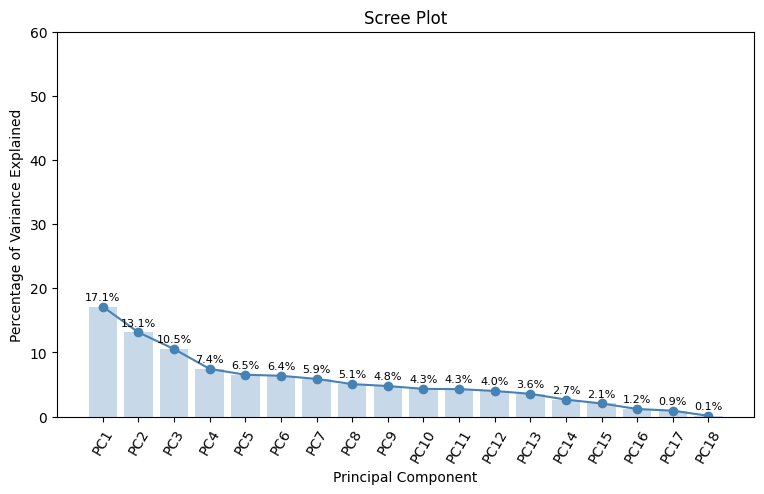

In [5]:
var_pct = pca.explained_variance_ratio_ * 100
plt.figure(figsize=(9,5))
plt.plot(pcs, var_pct, "o-", color="steelblue"); plt.bar(pcs, var_pct, alpha=.3, color="steelblue")
for i, v in enumerate(var_pct): plt.text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=8)
plt.ylim(0, 60); plt.xticks(rotation=60)
plt.title("Scree Plot"); plt.xlabel("Principal Component"); plt.ylabel("Percentage of Variance Explained"); plt.show()

**Q6. PCA biplot with non-overlapping labels and a title**

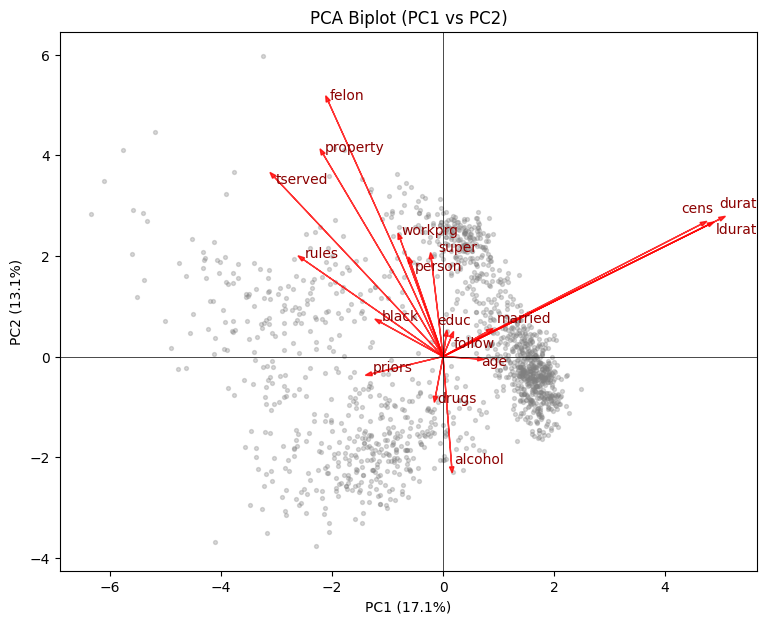

In [6]:
!pip -q install adjustText
from adjustText import adjust_text

scores = pca.transform(data_scaled)
load = pca.components_[:2].T                      # variable loadings on PC1, PC2
scale = np.abs(scores[:, :2]).max() * 0.8 / np.abs(load).max()

fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(scores[:, 0], scores[:, 1], s=8, alpha=.3, color="grey")
texts = []
for i, name in enumerate(data_scaled.columns):
    ax.arrow(0, 0, load[i, 0]*scale, load[i, 1]*scale, color="red", head_width=.08, alpha=.8)
    texts.append(ax.text(load[i, 0]*scale, load[i, 1]*scale, name, color="darkred"))
adjust_text(texts, ax=ax)                           # keeps labels from overlapping
ax.axhline(0, color="k", lw=.5); ax.axvline(0, color="k", lw=.5)
ax.set_xlabel(f"PC1 ({var_pct[0]:.1f}%)"); ax.set_ylabel(f"PC2 ({var_pct[1]:.1f}%)")
ax.set_title("PCA Biplot (PC1 vs PC2)"); plt.show()

**Q7. PCA scores in `pca_scores` – first six rows**

In [7]:
pca_scores = pd.DataFrame(scores, columns=pcs)
pca_scores.head(6)

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16,PC17,PC18
0,1.267303,0.108239,2.123873,0.997141,-0.682145,-0.831122,-1.226809,1.442345,-0.850831,-0.613087,0.293300,0.759227,1.027253,0.307427,0.297162,0.129275,-0.071924,-0.024163
1,0.282922,2.506651,-1.175236,0.982650,0.704604,-0.699117,0.445279,-0.809381,0.689592,0.225292,0.318623,-0.462660,0.553634,0.165504,-0.133196,0.159986,-0.055169,-0.001959
2,-2.946097,-0.387870,-1.098921,-1.599302,1.431960,-0.275810,-0.054277,0.916575,-1.132801,-1.505180,-0.275060,-0.600439,0.903001,0.336602,-0.595550,0.430802,-1.324478,-0.173813
3,-2.704402,1.341142,-0.239289,-1.153910,1.020690,0.014775,-1.986016,-0.542362,0.358285,0.285968,0.601412,-0.218005,0.322566,-0.323750,-0.106764,-0.466750,-0.025781,-0.165338
4,1.935934,-0.471235,-1.050214,-1.444742,0.978594,1.230277,-1.370149,-0.841687,0.167090,0.020981,-0.332112,1.034253,-0.230037,-0.441290,0.198576,0.132780,0.001078,0.051271
5,1.374178,0.465301,-1.194255,0.786881,1.146272,0.583206,0.999551,0.185939,0.782925,-0.793847,0.682528,0.726641,0.194578,-0.245281,0.150452,0.149132,-0.075443,0.016569


**Q8. Scatter plot of PC1 vs PC2 (blue circular points, registration number in title)**

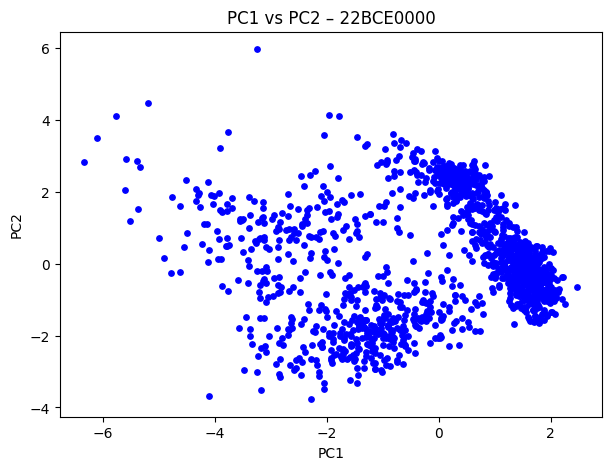

In [8]:
plt.figure(figsize=(7,5))
plt.scatter(pca_scores["PC1"], pca_scores["PC2"], color="blue", marker="o", s=15)
plt.title(f"PC1 vs PC2 – {REG_NO}"); plt.xlabel("PC1"); plt.ylabel("PC2"); plt.show()